# 1. Introduction
## What drives success for teams in the FIFA world cup and what factors influence match outcomes?
Objectives:
- Explore historical World Cup performance
- Investigate factors associated with tournament success
- Examine player and team characteristics
- Identify trends and correlations

BRAIN DUMP (DELETE LATER)

Areas to investigate:

- success score = max stage * count?
- no of wins / appearances in finals as a % for overall for each team over all matches not just finals
- in any of their games against any teams, win or lose, calc goal diff and get average so who scores most goals relative to their opponent
- higher goal difference shows aggression -- + or - so - means youre conceding more than you score.
- average player age?? age range/median/etc - correlate age to athleticism
- no of caps correlate to wins, avergae caps in team per WC , outside and and inside the world cup. find datasets external - all matches they played ever, combine and groupby player, another column to see if in world cups
- maybe see assists in other data
- all data before the WC ie between tournaments, no of unique players, gov funding

investigate the top 3 teams and why theyre the most successful.

Top 3 of all time in terms of winning FIFA tournament:
1. Brazil
2. Italy
3. Argentina

## 2. Data Loading & Initial Exploration


### Import packages

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors
import seaborn as sns
from datetime import datetime
import re
from pathlib import Path
import datetime 
from scipy import stats
from scipy.optimize import curve_fit
import pprint as pp

### Load Raw Data

In [ ]:
# Contains 49,393 International football results from 1872 to 2026. The matches range from FIFA World Cup to FIFI Wild Cup to regular friendly matches. 
# Used for analysing historical WC success
fp1 = Path.cwd().parent/'data'/'International_football_results_1872_to_2026'/'results.csv'
df = pd.read_csv(fp1)

# Contains 183 matches. Full match-level data including teams, scores, stage, venue, city, country, date, and match notes.
# Used for
fp2 = Path.cwd().parent/'data'/'world_cup_complete_dataset'/'wc_all_matches.csv'
df2 = pd.read_csv(fp2)

# Contains 48 qualified teams. Group assignment, confederation, FIFA rank, head coach, best-ever World Cup result, and 2026 debut indicator.
# Used for
fp3 = Path.cwd().parent/"data"/"world_cup_complete_dataset"/"wc_2026_teams.csv"
teams_df = pd.read_csv(fp3)

# Contains data on ~ 17,000 FIFA football players including but not limited to player names, nationalities, clubs, player ratings, potential, positions, ages, and various skill attributes.
# Used for 
fp4 = Path.cwd().parent/"data"/"players_data.csv"
players_df = pd.read_csv(fp4)

# Contains player performance attributes e.g assists, yellow cards, minutes played etc.
# Used for 
fp5 = Path.cwd().parent/"data"/"player_performances.csv"
perform_df = pd.read_csv(fp5)

# Contains information about each player such as their height, citizenship, date of birth etc.
# Used for  
fp6 = Path.cwd().parent/"data"/"player_profiles.csv"
profiles_df = pd.read_csv(fp6)

### Initial Exploration

In [347]:
df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,higher_score_for_home
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False,True
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False,True
3,1875-03-06,England,Scotland,2.0,2.0,Friendly,London,England,False,False
4,1876-03-04,Scotland,England,3.0,0.0,Friendly,Glasgow,Scotland,False,True


In [359]:
print(df.describe())
print(df.info())

         home_score    away_score
count  49501.000000  49501.000000
mean       1.757197      1.181936
std        1.773821      1.401655
min        0.000000      0.000000
25%        1.000000      0.000000
50%        1.000000      1.000000
75%        2.000000      2.000000
max       31.000000     21.000000
<class 'pandas.DataFrame'>
RangeIndex: 49505 entries, 0 to 49504
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   49505 non-null  str    
 1   home_team              49505 non-null  str    
 2   away_team              49505 non-null  str    
 3   home_score             49501 non-null  float64
 4   away_score             49501 non-null  float64
 5   tournament             49505 non-null  str    
 6   city                   49505 non-null  str    
 7   country                49505 non-null  str    
 8   neutral                49505 non-null  bool   
 9   higher_score_for_ho

In [360]:
df2.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner,goal_diff_winner,goal_diff_loser
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match,France,3,-3
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN,USA,3,-3
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN,Yugoslavia,1,-1
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN,Uruguay,1,-1
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN,Argentina,3,-3


In [364]:
print(df2.describe())
print(df2.info())

              year      score1      score2  goal_diff_winner  goal_diff_loser
count   184.000000  184.000000  184.000000        184.000000       184.000000
mean   1984.260870    2.358696    1.152174          1.717391        -1.717391
std      27.962844    1.746700    1.436714          1.520901         1.520901
min    1930.000000    0.000000    0.000000          0.000000        -9.000000
25%    1962.000000    1.000000    0.000000          1.000000        -2.000000
50%    1990.000000    2.000000    1.000000          1.000000        -1.000000
75%    2010.000000    3.000000    2.000000          2.000000        -1.000000
max    2022.000000    9.000000   10.000000          9.000000         0.000000
<class 'pandas.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   year              184 non-null    int64
 1   stage             184 non-null    str  
 2   team1             1

In [362]:
teams_df.head()

,team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026,best_stage_clean,best_stage_score
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No,Quarter-finals,3
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No,Group stage,1
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No,Semi-finals,4
3,Czechia,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No,Runner-up,6
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No,Group stage,1


In [363]:
print(teams_df.describe())
print(teams_df.info())

       fifa_rank  best_stage_score
count  48.000000         48.000000
mean   34.062500          3.104167
std    24.577629          2.345113
min     1.000000          0.000000
25%    13.750000          1.000000
50%    29.500000          2.500000
75%    52.250000          5.000000
max    95.000000          7.000000
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   team              48 non-null     str  
 1   group             48 non-null     str  
 2   confederation     48 non-null     str  
 3   fifa_rank         48 non-null     int64
 4   coach             48 non-null     str  
 5   best_wc_result    48 non-null     str  
 6   debut_2026        48 non-null     str  
 7   best_stage_clean  48 non-null     str  
 8   best_stage_score  48 non-null     int64
dtypes: int64(2), str(7)
memory usage: 3.5 KB
None


In [365]:
players_df.head()

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,39,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,1992-02-14,34,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,1993-03-15,33,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,1991-06-04,35,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,1991-06-20,35,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [366]:
print(players_df.describe())
print(players_df.info())

                       birth_date           age     height_cm    weight_kgs  \
count                       17954  17954.000000  17954.000000  17954.000000   
mean   1993-02-17 21:53:21.381307     33.308845    174.946921     75.301047   
min           1973-02-01 00:00:00     24.000000    152.400000     49.900000   
25%           1989-11-02 00:00:00     30.000000    154.940000     69.900000   
50%           1993-06-30 00:00:00     33.000000    175.260000     74.800000   
75%           1996-12-30 00:00:00     37.000000    185.420000     79.800000   
max           2002-02-26 00:00:00     53.000000    205.740000    110.200000   
std                           NaN      4.699151     14.029449      7.083684   

       overall_rating     potential    value_euro      wage_euro  \
count    17954.000000  17954.000000  1.769900e+04   17708.000000   
mean        66.240169     71.430935  2.479280e+06    9902.134628   
min         47.000000     48.000000  1.000000e+04    1000.000000   
25%         62.0

In [367]:
perform_df.head()

,player_id,season_name,competition_id,competition_name,team_id,team_name,nb_in_group,nb_on_pitch,goals,assists,own_goals,subed_in,subed_out,yellow_cards,second_yellow_cards,direct_red_cards,penalty_goals,minutes_played,goals_conceded,clean_sheets
0,1,08/09,OBLG,NOFV-Oberliga Süd,4825,FC Eilenburg,9,9,0.0,0,0,0,2,0,0,1,0,NaN,0,0
1,1,07/08,RS,Regionalliga Süd,1526,FSV Ludwigshafen Oggersheim,22,22,1.0,0,0,3,8,1,0,0,0,1580.0,0,0
2,1,06/07,L2,2. Bundesliga,996,TuS Koblenz,10,4,0.0,0,0,4,0,0,0,0,0,NaN,0,0
3,1,06/07,DFB,DFB-Pokal,996,TuS Koblenz,1,0,0.0,0,0,0,0,0,0,0,0,NaN,0,0
4,1,05/06,L2,2. Bundesliga,66,SpVgg Unterhaching,26,14,1.0,1,0,12,1,1,0,0,0,388.0,0,0


In [368]:
print(perform_df.describe())
print(perform_df.info())

          player_id       team_id   nb_in_group   nb_on_pitch         goals  \
count  1.878719e+06  1.878719e+06  1.878719e+06  1.878719e+06  1.740517e+06   
mean   2.916295e+05  1.069298e+04  9.929085e+00  8.156783e+00  9.527192e-01   
std    2.922079e+05  1.770314e+04  1.084346e+01  9.865284e+00  2.283932e+00   
min    1.000000e+00  1.000000e+00  1.000000e+00  0.000000e+00  0.000000e+00   
25%    5.549400e+04  7.980000e+02  2.000000e+00  1.000000e+00  0.000000e+00   
50%    1.894820e+05  3.060000e+03  4.000000e+00  3.000000e+00  0.000000e+00   
75%    4.477680e+05  1.144900e+04  1.600000e+01  1.300000e+01  1.000000e+00   
max    1.453181e+06  1.345500e+05  5.100000e+01  5.100000e+01  5.000000e+01   

            assists     own_goals      subed_in     subed_out  yellow_cards  \
count  1.878719e+06  1.878719e+06  1.878719e+06  1.878719e+06  1.878719e+06   
mean   4.469455e-01  1.532853e-02  1.673163e+00  1.855993e+00  1.111522e+00   
std    1.247370e+00  1.300537e-01  3.035122e+00  3.

In [55]:
profiles_df.head()

C:\Users\bevamin\AppData\Local\Temp\ipykernel_14812\994322731.py:2: DtypeWarning: Columns (0: third_club_url, 1: third_club_name, 2: fourth_club_url, 3: fourth_club_name) have mixed types. Specify dtype option on import or set low_memory=False.
  profiles_df = pd.read_csv(fp)


,player_id,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,height,citizenship,...,on_loan_from_club_id,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death
0,1,silvio-adzic,Silvio Adzic (1),https://img.a.transfermarkt.technology/portrai...,NaN,1980-09-23,Grünstadt,Germany,0.0,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100011,everton-silva,Éverton Silva (100011),https://img.a.transfermarkt.technology/portrai...,Éverton José Modesto da Silva,1988-08-04,São João de Meriti,Brazil,171.0,Brazil,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,miroslav-klose,Miroslav Klose (10),https://img.a.transfermarkt.technology/portrai...,Miroslav Josef Klose,1978-06-09,Opole,Germany,184.0,Germany,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,john-thompson,John Thompson (10001),https://img.a.transfermarkt.technology/portrai...,John Paul Thompson,1981-10-12,Dublin,Ireland,183.0,Ireland,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100001,carlos-auzqui,Carlos Auzqui (100001),https://img.a.transfermarkt.technology/portrai...,Carlos Daniel Auzqui,1991-03-16,Longchamps,Argentina,180.0,Argentina,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [369]:
print(profiles_df.describe())
print(profiles_df.info())

          player_id        height  current_club_id  player_agent_id  \
count  9.267100e+04  92667.000000     92671.000000     38057.000000   
mean   4.822020e+05    144.619908     17268.764835      5654.314160   
std    3.894922e+05     73.368611     28780.506345      4038.521566   
min    1.000000e+00      0.000000         1.000000         1.000000   
25%    1.214005e+05    171.000000       123.000000      2325.000000   
50%    4.021140e+05    180.000000      1533.000000      4906.000000   
75%    7.989040e+05    185.000000     22177.000000      8598.000000   
max    1.459023e+06    210.000000    134553.000000     15015.000000   

       on_loan_from_club_id  
count           3758.000000  
mean           14245.704364  
std            23763.128575  
min                2.000000  
25%              738.000000  
50%             3901.000000  
75%            14926.000000  
max           132806.000000  
<class 'pandas.DataFrame'>
RangeIndex: 92671 entries, 0 to 92670
Data columns (total 34 co

## 3. Data Cleaning & Feature Engineering

### Data Cleaning

In [17]:
'''Added match_winner column'''

df2['match_winner'] = df2.apply(lambda x: x['team1'] if x['score1'] > x['score2'] else (x['team2'] if x['score2'] > x['score1'] else 'Draw'), axis=1)
df2.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
0,1930,Group Stage,France,4,1,Mexico,Estadio Centenario,Montevideo,Uruguay,1930-07-13,First ever WC match,France
1,1930,Group Stage,USA,3,0,Belgium,Estadio Centenario,Montevideo,Uruguay,1930-07-13,NaN,USA
2,1930,Group Stage,Yugoslavia,2,1,Brazil,Estadio Centenario,Montevideo,Uruguay,1930-07-14,NaN,Yugoslavia
3,1930,Group Stage,Uruguay,1,0,Peru,Estadio Centenario,Montevideo,Uruguay,1930-07-18,NaN,Uruguay
4,1930,Group Stage,Argentina,6,3,USA,Estadio Centenario,Montevideo,Uruguay,1930-07-26,NaN,Argentina


In [19]:
'''some match winners results are Draw, so need to check notes to see who actually won, eg if it went to penalties'''

finals_with_notes = finals_df[finals_df['match_winner'] == 'Draw'] 
finals_with_notes.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
106,1994,Final,Brazil,0,0,Italy,Rose Bowl,Pasadena,USA,1994-07-17,Brazil win 3-2 pens - Baggio misses,Draw
135,2006,Final,Italy,1,1,France,Olympiastadion,Berlin,Germany,2006-07-09,Zidane headbutt - Italy win 5-3 pens,Draw
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final,Draw


In [20]:
'''based on above, need to change match winner column for those specific matches to reflect actual winner.'''

df2.loc[106, 'match_winner'] = 'Brazil'
df2.loc[135, 'match_winner'] = 'Italy'
df2.loc[183, 'match_winner'] = 'Argentina'

'''code to check that results were changed'''
df2.loc[[106, 135, 183]]

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
106,1994,Final,Brazil,0,0,Italy,Rose Bowl,Pasadena,USA,1994-07-17,Brazil win 3-2 pens - Baggio misses,Brazil
135,2006,Final,Italy,1,1,France,Olympiastadion,Berlin,Germany,2006-07-09,Zidane headbutt - Italy win 5-3 pens,Italy
183,2022,Final,Argentina,3,3,France,Lusail Stadium,Lusail,Qatar,2022-12-18,AET - Argentina win 4-2 pens - GOAT final,Argentina


In [144]:
teams_df['best_stage_clean'] = teams_df['best_wc_result'].map(text_only)
teams_df.head()

,team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026,best_stage_clean
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No,Quarter-finals
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No,Group stage
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No,Semi-finals
3,Czechia,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No,Runner-up
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No,Group stage


In [36]:
'''change birth_date column from str to date (US - MM-DD-YYYY)'''

players_df['birth_date'] = pd.to_datetime(players_df['birth_date'])

'''get today's date'''
today = pd.Timestamp.today()
print(today)

'''change age column to reflect current actual age'''
players_df['age'] = (today.year - players_df['birth_date'].dt.year)
players_df.head()

2026-09-29 10:48:00.121149


,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,39,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,1992-02-14,34,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,1993-03-15,33,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,1991-06-04,35,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,1991-06-20,35,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


### Feature Engineering

## 4. Match Outcomes

### Neutral Venue Analysis

True ie higher score for home team:  18451
False ie NOT a higher score for home team:  17909
Neutral game count:  13145
all rows count=  49505
percent home wins: 37.27%
percent away wins: 36.18%
percent neutral: 26.55%


Text(0.5, 1.0, 'Percentage splits of match wins depending on location')

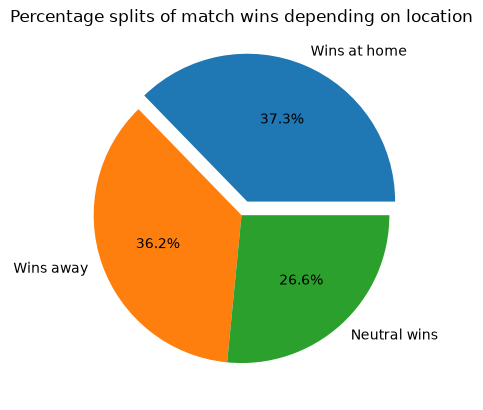

In [8]:
'''Does playing at a neutral venue affect score? ie if team played in home country?'''   

# new column to show if home score was greater than away score
df['higher_score_for_home'] = np.where(((df['home_score'] > df['away_score']) & (df['neutral'] == False)), True, False)

true_count = df['higher_score_for_home'].sum() # counts Trues only
false_count = (~df['higher_score_for_home']).sum()
neutral_count = len(df[df['neutral'] == True])
false_count -= neutral_count
all_rows = true_count + false_count + neutral_count

percent_home_win = (true_count / all_rows) * 100
percent_away_win = (false_count / all_rows) * 100
percent_neutral = (neutral_count / all_rows) * 100

print(f'True ie higher score for home team: ', true_count)
print(f'False ie NOT a higher score for home team: ', false_count)
print(f'Neutral game count: ', neutral_count)
print(f'all rows count= ', true_count + false_count + neutral_count)
print(f"percent home wins: {round(percent_home_win, 2)}%\npercent away wins: {round(percent_away_win,2)}%\npercent neutral: {round(percent_neutral,2)}%")

# plot pie chart
values = [percent_home_win, percent_away_win, percent_neutral]
labels = ['Wins at home', 'Wins away', "Neutral wins"]
explode = (0.1, 0, 0)
plt.pie(values, labels=labels, autopct='%1.1f%%', explode=explode)
plt.title('Percentage splits of match wins depending on location')

## 5. Historical World Cup Success

<Axes: title={'center': 'Top 10 Home Teams with Most Goals'}, xlabel='Team', ylabel='Total Home Goals'>

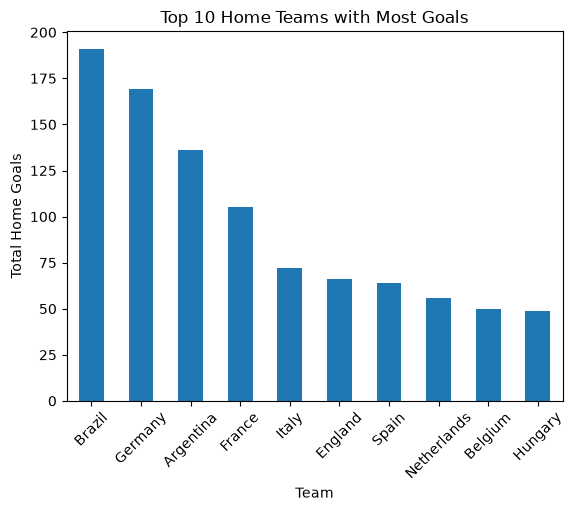

In [9]:
'''team with most home or away goals'''

# home team with most scores where tournament is FIFA World Cup
df[df['tournament'] == 'FIFA World Cup'].groupby('home_team')['home_score'].sum().sort_values(ascending=False).head(10).plot(kind='bar', title='Top 10 Home Teams with Most Goals', rot=45, ylabel = 'Total Home Goals', xlabel="Team")

<Axes: title={'center': 'Top 10 Away Teams with Most Goals'}, xlabel='away_team', ylabel='Total Away Goals'>

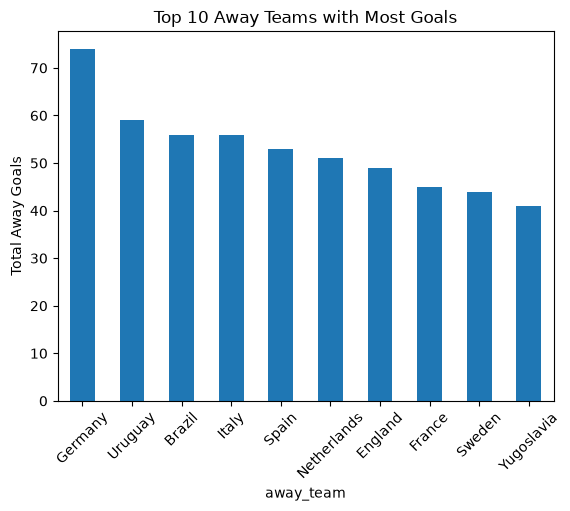

In [10]:
'''away team with most goals where tournament is FIFA World Cup'''
df[df['tournament'] == 'FIFA World Cup'].groupby('away_team')['away_score'].sum().sort_values(ascending=False).head(10).plot(kind='bar', title='Top 10 Away Teams with Most Goals', rot=45, ylabel = 'Total Away Goals')

home_team
Brazil         79.0
Germany        70.0
Argentina      52.0
Italy          45.0
France         44.0
England        36.0
Spain          35.0
Netherlands    32.0
Uruguay        25.0
Belgium        24.0
dtype: float64
[79. 70. 52. 45. 44. 36. 35. 32. 25. 24.]
Index(['Brazil', 'Germany', 'Argentina', 'Italy', 'France', 'England', 'Spain',
       'Netherlands', 'Uruguay', 'Belgium'],
      dtype='str', name='home_team')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Brazil'),
  Text(1, 0, 'Germany'),
  Text(2, 0, 'Argentina'),
  Text(3, 0, 'Italy'),
  Text(4, 0, 'France'),
  Text(5, 0, 'England'),
  Text(6, 0, 'Spain'),
  Text(7, 0, 'Netherlands'),
  Text(8, 0, 'Uruguay'),
  Text(9, 0, 'Belgium')])

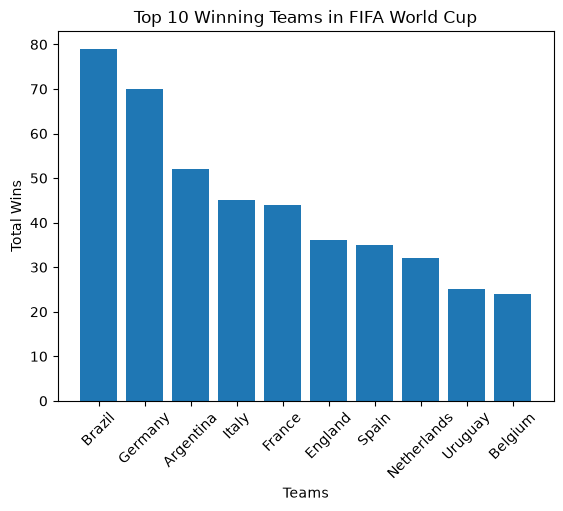

In [11]:
'''highest scoring team overall'''

# remove the rows where tournament is not FIFA World Cup
fifa_only_df = df[df['tournament'] == 'FIFA World Cup']

# team that won the most over time, so need to calculate total wins by doing their home score - away score depending on where they played
winning_team = fifa_only_df.copy()
winning_team['home_win'] = winning_team['home_score'] > winning_team['away_score']
winning_team['away_win'] = winning_team['away_score'] > winning_team['home_score']

winning_team_overall = winning_team.groupby('home_team')['home_win'].sum() + winning_team.groupby('away_team')['away_win'].sum()
print(winning_team_overall.sort_values(ascending=False).head(10))

winners_list = winning_team_overall.sort_values(ascending=False).head(10)
print((winners_list.values))
print((winners_list.index))

plt.bar(winners_list.index, winners_list.values)
plt.title('Top 10 Winning Teams in FIFA World Cup')
plt.ylabel('Total Wins')
plt.xlabel('Teams')
plt.xticks(rotation=45)

### Success by Era

8
<class 'numpy.ndarray'>
[Timestamp('1942-12-31 00:00:00'), Timestamp('1954-12-31 00:00:00'), Timestamp('1966-12-31 00:00:00'), Timestamp('1978-12-31 00:00:00'), Timestamp('1990-12-31 00:00:00'), Timestamp('2002-12-31 00:00:00'), Timestamp('2014-12-31 00:00:00'), Timestamp('2026-07-11 00:00:00')]


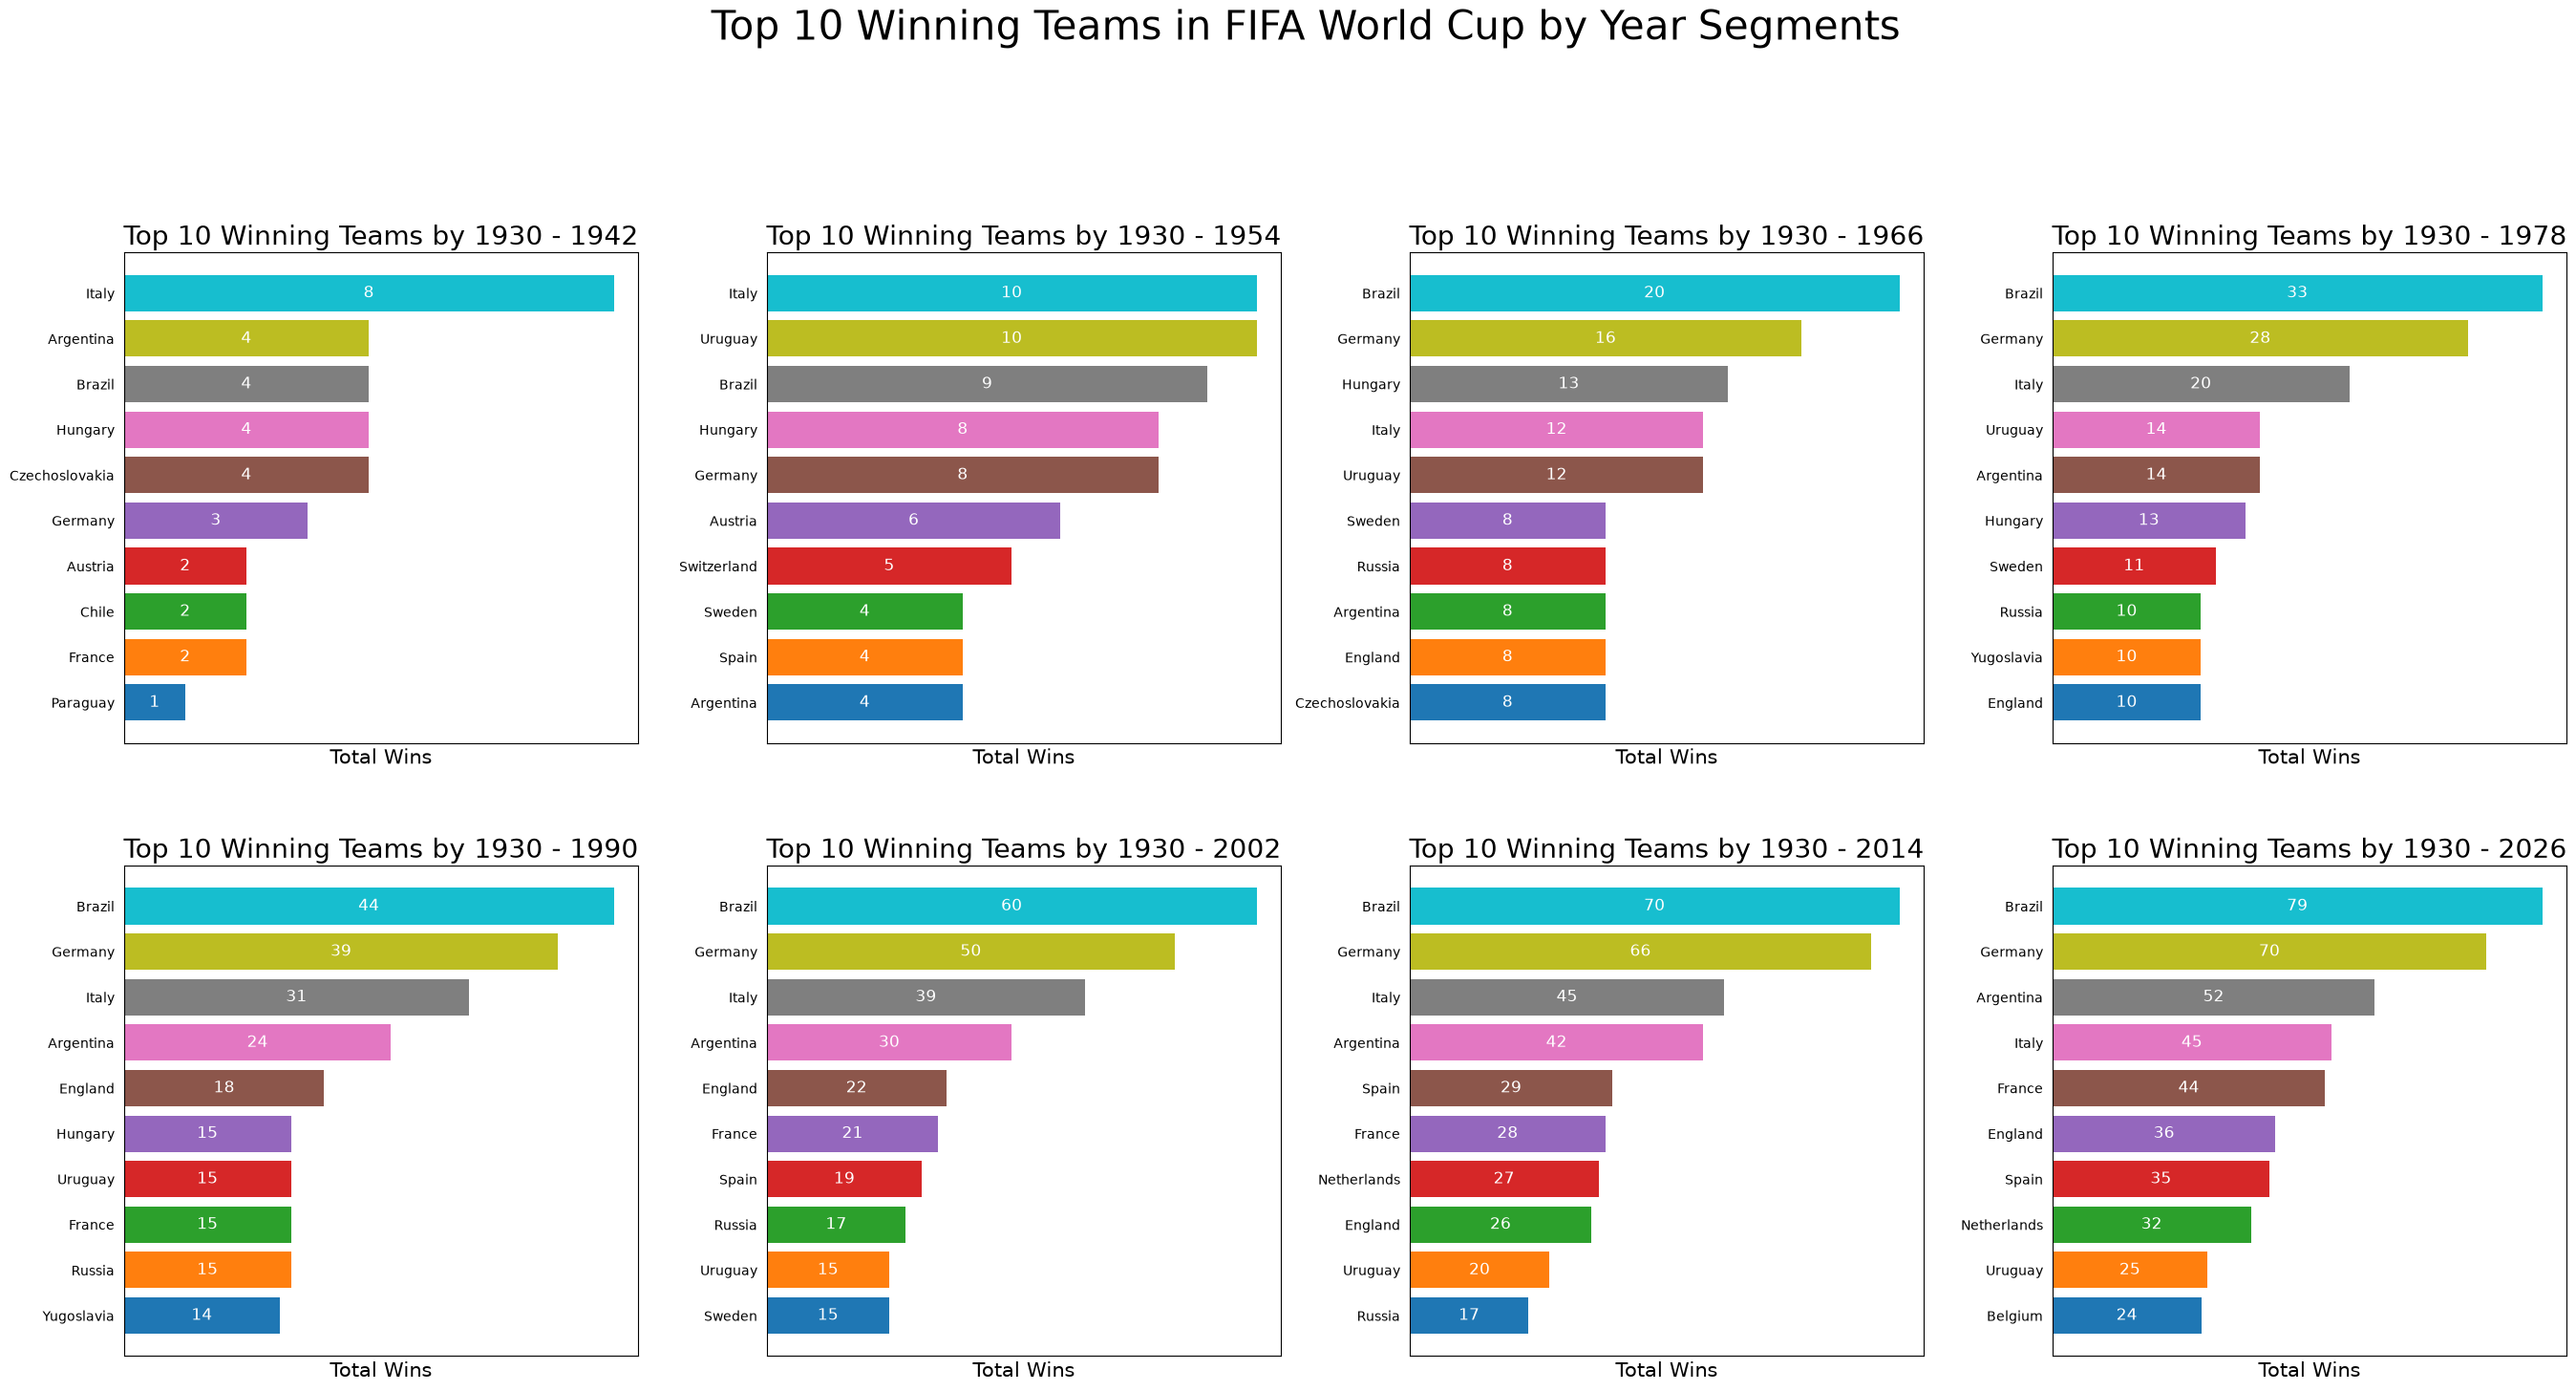

In [12]:
# SPLIT BY EVERY 20 YRS

#date from str to date
winning_team['date'] = pd.to_datetime(winning_team['date'], format='%Y-%m-%d')


earliest_date = winning_team.date.min()
latest_date = winning_team.date.max()

no_of_segments = (latest_date.year - earliest_date.year) // 12
print(no_of_segments)

fig, ax = plt.subplots(2, 4, figsize = (33, 15))
print(type(ax))

timepoints = [date for date in pd.date_range(start=earliest_date, end=latest_date, freq='12YE')]
timepoints.pop(0)
timepoints.append(latest_date)
print(timepoints)

flattened_ax = ax.flatten()

for n, date in enumerate(timepoints):
    filtered_df = winning_team[winning_team['date'] < date]
    current_ax = flattened_ax[n]
    winning_team_overall = filtered_df.groupby('home_team')['home_win'].sum() + filtered_df.groupby('away_team')['away_win'].sum()
    winners_list = winning_team_overall.sort_values(ascending=False).head(10)
    winners_list.sort_values(ascending=True, inplace=True)
    p = current_ax.barh(winners_list.index, winners_list.values, color = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan'])
    fig.suptitle('Top 10 Winning Teams in FIFA World Cup by Year Segments', fontsize=30, y=1.05)
    current_ax.set_title(f'Top 10 Winning Teams by {earliest_date.year} - {date.year}', fontsize=20)
    current_ax.set_yticks(range(10))
    current_ax.set_xlabel('Total Wins', fontsize=15)
    current_ax.tick_params(axis='y', left=False)
    current_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    current_ax.bar_label(p, label_type='center', fmt='%d', fontsize=12, color='white')
    fig.subplots_adjust(hspace=0.25, wspace=0.25)



In [18]:
# filtered df to show only finals matches
finals_df = df2[(df2['stage'] == 'Final')]
finals_df.head()

,year,stage,team1,score1,score2,team2,venue,city,country,date,notes,match_winner
7,1930,Final,Uruguay,4,2,Argentina,Estadio Centenario,Montevideo,Uruguay,1930-07-30,First WC Final,Uruguay
14,1934,Final,Italy,2,1,Czechoslovakia,PNF Stadium,Rome,Italy,1934-06-10,AET,Italy
21,1938,Final,Italy,4,2,Hungary,Stade de Colombes,Paris,France,1938-06-19,NaN,Italy
33,1954,Final,West Germany,3,2,Hungary,Wankdorf,Bern,Switzerland,1954-07-04,Miracle of Bern,West Germany
40,1958,Final,Brazil,5,2,Sweden,Råsunda,Stockholm,Sweden,1958-06-29,Pelé scores 2 at 17,Brazil


In [21]:
# team who won the most world cups:
world_cup_winners = df2[df2['stage'] == 'Final'].groupby('match_winner').agg(years=('year', list), count=('year', 'count')).sort_values(by='count', ascending=False).reset_index()
world_cup_winners

,match_winner,years,count
0,Brazil,"[1958, 1962, 1970, 1994, 2002]",5
1,Italy,"[1934, 1938, 1982, 2006]",4
2,Argentina,"[1978, 1986, 2022]",3
3,West Germany,"[1954, 1974, 1990]",3
4,France,"[1998, 2018]",2
5,Germany,[2014],1
6,England,[1966],1
7,Spain,[2010],1
8,Uruguay,[1930],1


## 6. Team Performance Metrics

In [141]:
# get unique stage names
def text_only(x):
    '''Removes dates from the values to just get the stage name'''
    return re.sub(r'\s*\(.*\)', '', x)

unique_results = teams_df['best_wc_result'].apply(text_only).unique()
unique_results

<StringArray>
[  'Quarter-finals',      'Group stage',      'Semi-finals',
        'Runner-up',          'Winners',      'Third place',
      'Round of 16', 'First appearance']
Length: 8, dtype: str

In [29]:
# Brazil - goal difference (higher goal diff means more aggression)

# Brazil dataframe
brazil_team1 = df2[df2['team1'] == 'Brazil']
brazil_team2 = df2[df2['team2'] == 'Brazil']
brazil_df = pd.concat([brazil_team1, brazil_team2])

# new column - goal difference
df2['goal_diff_winner'] = df2.apply(lambda x: (x['score1'] - x['score2'] if x['team1'] == x['match_winner'] else (x['score2'] - x['score1'] if x['team2'] == x['match_winner'] else 0)),axis=1)
df2['goal_diff_loser'] = df2.apply(lambda x: (x['score1'] - x['score2'] if x['team1'] != x['match_winner'] else (x['score2'] - x['score1'] if x['team2'] != x['match_winner'] else 0)),axis=1)


In [199]:
''' Calculate average goal difference per team'''

def find_team_data(team_name: str):
    '''returns a copy of df2 for each team when they play as 'team1' and 'team2' '''
    team1_df = df2[df2['team1'] == team_name]
    team2_df = df2[df2['team2'] == team_name]
    team_df = pd.concat([team1_df, team2_df])
    return team_df.copy()

# getting unique team names as a list called 'teams'
teams = df2['team1'].to_list()
other_teams = df2['team2'].to_list()
teams.extend(other_teams)
teams = list(set(teams))
teams.sort()

# initialise a dictionary to store our results
team_dfs = {}
for team in teams:
    current_df = find_team_data(team)
    team_dfs[team] = current_df

# 'data' is a dataframe for each team. Add new column to get goal difference depending on whether the team won or lost
for team, data, in team_dfs.items():
    data[f"{team} goal diff"] = data.apply(lambda x: x['goal_diff_winner'] if team == x['match_winner'] else x['goal_diff_loser'], axis=1)

# dictionary to store teams' average goal differences
avg_goal_diff = {}
for team, data, in team_dfs.items():
    average = data[f"{team} goal diff"].mean()
    avg_goal_diff[team] = average

# Converting dictionary to series
goal_diff_df = pd.Series(avg_goal_diff)
goal_diff_df.sort_values(ascending=False)

Denmark             5.000000
Hungary             2.285714
Ecuador             2.000000
Russia              1.400000
Germany             1.272727
Ghana               1.000000
East Germany        1.000000
Senegal             1.000000
Nigeria             1.000000
Colombia            1.000000
France              0.960000
Brazil              0.875000
Italy               0.800000
Bulgaria            0.666667
Netherlands         0.466667
Argentina           0.259259
Romania             0.000000
Japan               0.000000
Ireland             0.000000
Algeria             0.000000
South Africa        0.000000
Turkey              0.000000
Soviet Union       -0.250000
Chile              -0.333333
Portugal           -0.333333
Uruguay            -0.333333
West Germany       -0.375000
Spain              -0.400000
North Korea        -0.500000
Morocco            -0.500000
England            -0.611111
Croatia            -0.625000
Poland             -0.666667
Belgium            -0.777778
Czechoslovakia

### Best Stage Reached

In [146]:
'''Map the stages to a numeric score and add this as a new column'''

stage_map = {
'First appearance': 0,
'Group stage': 1,
'Round of 16': 2,
'Quarter-finals': 3,
'Semi-finals': 4,
'Third place': 5,
'Runner-up': 6,
'Winners': 7
}

teams_df['best_stage_score'] = teams_df['best_stage_clean'].map(stage_map)
teams_df.head()

,team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026,best_stage_clean,best_stage_score
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No,Quarter-finals,3
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No,Group stage,1
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No,Semi-finals,4
3,Czechia,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No,Runner-up,6
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No,Group stage,1


                      team  best_stage_score  avg_goal_diff
0                   Mexico                 3      -1.600000
1             South Africa                 1       0.000000
2              South Korea                 4      -1.333333
3                  Czechia                 6            NaN
4                   Canada                 1            NaN
5              Switzerland                 3      -2.000000
6                    Qatar                 1      -2.000000
7   Bosnia and Herzegovina                 1            NaN
8                   Brazil                 7       0.875000
9                  Morocco                 4      -0.500000
10                   Haiti                 1            NaN
11                Scotland                 1      -1.000000
12                     USA                 5      -1.625000
13                Paraguay                 3      -2.500000
14               Australia                 2      -1.000000
15                  Turkey              

,best_stage_score,avg_goal_diff
best_stage_score,1.000000,0.244341
avg_goal_diff,0.244341,1.000000


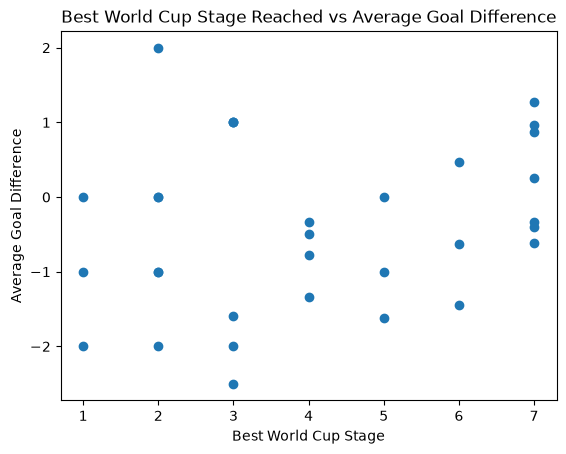

In [324]:
'''Correlate best_stage_score with other factors e.g avg goals scored per game/avg goal diff/ possession etc'''

filtered_corr_df = teams_df[['team', 'best_stage_score']]

# Corrected this as it was previously 'Turkiye' causing a NaN 
filtered_corr_df.loc[15, 'team'] = 'Turkey'

'''Best world cup stage vs average goal difference'''

def map_goal_diff(team):
    '''iterate through the avg_goal_diff dict and return the goal_diff'''
    for teamname, goal_diff in avg_goal_diff.items():
        if team == teamname:
            return goal_diff
    return None          

filtered_corr_df['avg_goal_diff'] = filtered_corr_df['team'].map(map_goal_diff)

fig, ax = plt.subplots()
ax.scatter(filtered_corr_df['best_stage_score'], filtered_corr_df['avg_goal_diff'])
ax.set_xlabel('Best World Cup Stage')
ax.set_ylabel('Average Goal Difference')
ax.set_title('Best World Cup Stage Reached vs Average Goal Difference')

print(filtered_corr_df)

corr_coeff = filtered_corr_df[['best_stage_score', 'avg_goal_diff']].corr()
corr_coeff



                avg_goals_scored_per_game
Denmark                          6.000000
Austria                          5.000000
Russia                           4.333333
Sweden                           3.500000
Australia                        3.000000
France                           2.866667
Uruguay                          2.857143
Brazil                           2.709677
Belgium                          2.666667
Netherlands                      2.400000
Germany                          2.357143
Argentina                        2.222222
Yugoslavia                       2.000000
Colombia                         1.500000
Spain                            1.333333
England                          1.285714
Portugal                         1.000000
Morocco                          0.500000
Bolivia                          0.000000
Bulgaria                         3.666667
Hungary                          3.250000
Germany                          2.375000
Japan                            1

,best_stage_score,avg_goals_scored_per_game
best_stage_score,1.000000,-0.088339
avg_goals_scored_per_game,-0.088339,1.000000


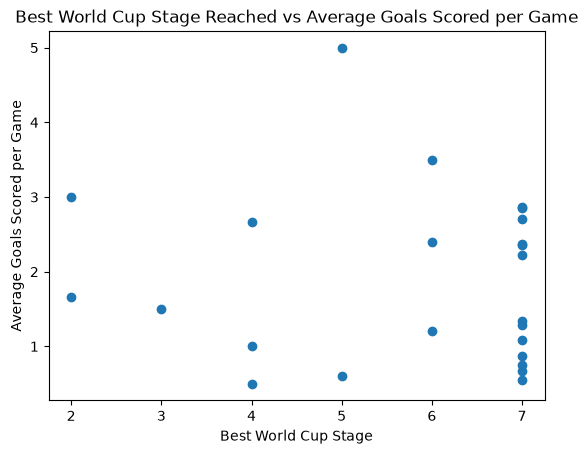

In [340]:
'''Best World Cup Stage Reached vs avg number of goals scored per game'''

# need an average score1 for team1 and score 2 for team2  group by team1/team2, 

avg_goals_game_t1 = df2.groupby('team1').agg(avg_goals_scored_per_game=('score1', 'mean')).sort_values(by='avg_goals_scored_per_game', ascending=False)
avg_goals_game_t2 = df2.groupby('team2').agg(avg_goals_scored_per_game=('score2', 'mean')).sort_values(by='avg_goals_scored_per_game', ascending=False)
combined_avg_goals_game = pd.concat([avg_goals_game_t1, avg_goals_game_t2])
combined_avg_goals_game.drop_duplicates(inplace=True)

avg_goals_vs_filtered_corr_df = pd.merge(combined_avg_goals_game, filtered_corr_df, how='left', left_index=True, right_on='team')
avg_goals_vs_filtered_corr_df.head(10)

fig, ax = plt.subplots()
ax.scatter(avg_goals_vs_filtered_corr_df['best_stage_score'], avg_goals_vs_filtered_corr_df['avg_goals_scored_per_game'])
ax.set_xlabel('Best World Cup Stage')
ax.set_ylabel('Average Goals Scored per Game')
ax.set_title('Best World Cup Stage Reached vs Average Goals Scored per Game')

corr_coeff = avg_goals_vs_filtered_corr_df[['best_stage_score', 'avg_goals_scored_per_game']].corr()
corr_coeff

,best_stage_score,avg_goals_conceded_per_game
best_stage_score,1.000000,-0.323852
avg_goals_conceded_per_game,-0.323852,1.000000


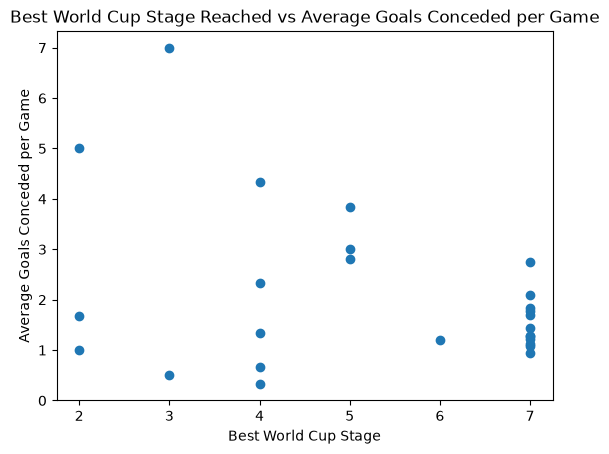

In [342]:
'''goals conceded vs stage reached'''
# for team1 --> score2
# for team2 --> score1

# need an average score2 for team1 and score1 for team2  group by team1/team2, 

avg_concede_game_t1 = df2.groupby('team1').agg(avg_goals_conceded_per_game=('score2', 'mean')).sort_values(by='avg_goals_conceded_per_game', ascending=False)
avg_concede_game_t2 = df2.groupby('team2').agg(avg_goals_conceded_per_game=('score1', 'mean')).sort_values(by='avg_goals_conceded_per_game', ascending=False)
combined_avg_concede_game = pd.concat([avg_concede_game_t1, avg_concede_game_t2])
combined_avg_concede_game.drop_duplicates(inplace=True)

avg_conceded_vs_filtered_corr_df = pd.merge(combined_avg_concede_game, filtered_corr_df, how='left', left_index=True, right_on='team')
avg_conceded_vs_filtered_corr_df.head(10)

fig, ax = plt.subplots()
ax.scatter(avg_conceded_vs_filtered_corr_df['best_stage_score'], avg_conceded_vs_filtered_corr_df['avg_goals_conceded_per_game'])
ax.set_xlabel('Best World Cup Stage')
ax.set_ylabel('Average Goals Conceded per Game')
ax.set_title('Best World Cup Stage Reached vs Average Goals Conceded per Game')

corr_coeff = avg_conceded_vs_filtered_corr_df[['best_stage_score', 'avg_goals_conceded_per_game']].corr()
corr_coeff


## 7. Player Quality Analysis

In [37]:
players_df['value_euro'].reset_index().head(5)

,index,value_euro
0,0,110500000.0
1,1,69500000.0
2,2,73000000.0
3,3,62000000.0
4,4,60000000.0


Youngest: 24
Oldest: 53
Mean: 33.3
Median: 33.0


Text(0, 0.5, 'Count')

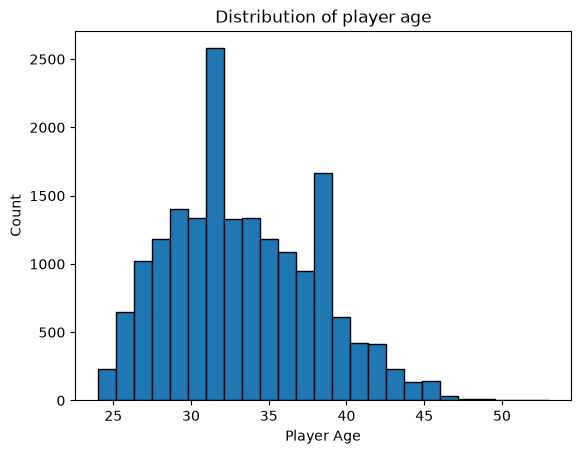

In [38]:
""" Age """

min_age = round(players_df['age'].min(), 1)
max_age = round(players_df['age'].max(), 1)
avg_age = round(players_df['age'].mean(), 1)
med_age = round(players_df['age'].median(), 1)

print(f"Youngest: {min_age}\nOldest: {max_age}\nMean: {avg_age}\nMedian: {med_age}")

plt.hist(players_df['age'], bins=25, edgecolor='black')
plt.title("Distribution of player age")
plt.xlabel("Player Age")
plt.ylabel("Count")

Text(0.5, 0, 'Market Value')

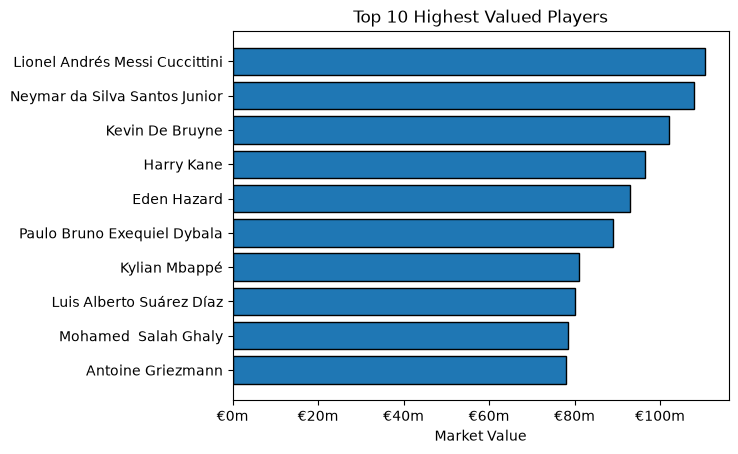

In [39]:
''' Top 10 valued players'''

top_10_valued = players_df.nlargest(10, 'value_euro')
categories = top_10_valued['full_name']
values = top_10_valued['value_euro']
plt.barh(categories, values, edgecolor='black')
plt.gca().invert_yaxis()
plt.title('Top 10 Highest Valued Players')
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'€{x/1000000:.0f}m'))
plt.xlabel('Market Value')

In [40]:
''' Most common nationality of the top 10 valued players '''
mode_nationality = top_10_valued.groupby('nationality').agg(no_of_top_players=('nationality', 'count')).sort_values(by='no_of_top_players', ascending=False)
mode_nationality

,no_of_top_players
nationality,
Argentina,2
Belgium,2
France,2
Brazil,1
Egypt,1
England,1
Uruguay,1


In [41]:
''' Top 3 Rated Players per Country '''

best_players = players_df.sort_values(by='overall_rating', ascending=False)\
    .groupby('nationality').head(3)\
    .groupby('nationality').agg(players=('name', list),\
     ratings=('overall_rating', list), top_players_average=('overall_rating', 'mean')).sort_values(by='top_players_average', ascending=False)

best_players.head(10)

,players,ratings,top_players_average
nationality,,,
Argentina,"[L. Messi, P. Dybala, S. Agüero]","[94, 89, 89]",90.666667
Belgium,"[K. De Bruyne, E. Hazard, T. Courtois]","[91, 91, 89]",90.333333
Spain,"[De Gea, Sergio Ramos, David Silva]","[91, 90, 90]",90.333333
Uruguay,"[L. Suárez, D. Godín, E. Cavani]","[91, 90, 89]",90.000000
Brazil,"[Neymar Jr, Thiago Silva, Coutinho]","[92, 88, 88]",89.333333
Germany,"[T. Kroos, M. Neuer, M. ter Stegen]","[90, 89, 89]",89.333333
France,"[N. Kanté, A. Griezmann, K. Mbappé]","[89, 89, 88]",88.666667
Italy,"[G. Chiellini, G. Buffon, L. Insigne]","[90, 88, 88]",88.666667
Portugal,"[Cristiano Ronaldo, Bernardo Silva, A. Lopes]","[94, 86, 85]",88.333333


In [42]:
'''Top 3 of all time in terms of winning FIFA tournament:
    1. Brazil 5x
    2. Italy 4x
    3. Argentina 3x
    4. France have also won 2x

    Do the top winning teams win because they have the best players?
    average player rating in those teams '''

'''Mean player rating by national team'''
overall_ratings = players_df.groupby('national_team').agg(mean_player_rating=('overall_rating', 'mean')).sort_values(by='mean_player_rating', ascending=False)
rounded_ratings = round(overall_ratings, 2).head(10)
rounded_ratings

,mean_player_rating
national_team,
Spain,84.48
Germany,84.04
Belgium,83.42
France,83.30
Dalian YiFang FC,83.00
FC Porto,82.20
Argentina,82.12
Italy,81.50
England,81.26


In [43]:
# min, median, mean, max player ratings for whole df^^^ to compare to

med_rating = round(players_df['overall_rating'].median(), 1)
print(med_rating)

66.0


In [44]:
winning_teams = list(world_cup_winners['match_winner'])

# just want player average for winning_teams

national_teams = list(players_df['national_team'].unique().dropna())
print(winning_teams)
print(national_teams)

winners_means = {}
for team in winning_teams:
     if team not in national_teams:
          if team == 'West Germany':
               winners_means[team] = med_rating
          continue
     rating_mean = players_df.groupby('national_team')['overall_rating'].mean() 
     winners_means[team] = rating_mean.loc[team]
print(winners_means)


winners_means = winners_means.values()

['Brazil', 'Italy', 'Argentina', 'West Germany', 'France', 'Germany', 'England', 'Spain', 'Uruguay']
['Argentina', 'Denmark', 'France', 'Italy', 'Netherlands', 'Germany', 'Uruguay', 'Spain', 'Belgium', 'Egypt', 'Colombia', 'Sporting CP', 'Portugal', 'Dalian YiFang FC', 'Mexico', 'Brazil', 'England', 'Austria', 'Al Hilal', 'Iceland', 'Hungary', 'Wales', 'Cameroon', "Côte d'Ivoire", 'Australia', 'FC Porto', 'Romania', 'Russia', 'Chile', 'Norway', 'Peru', 'Venezuela', 'Sweden', 'Scotland', 'Canada', 'SL Benfica', 'Poland', 'Turkey', 'Northern Ireland', 'Santos Laguna', 'New Zealand', 'United States', 'Republic of Ireland', 'Ecuador', 'Pachuca', 'Slovenia', 'Czech Republic', 'Racing Club', 'FC Red Bull Salzburg', 'Puebla FC', 'Greece', 'Universidad de Chile', 'Club Tijuana', 'Paraguay', 'Switzerland', 'Querétaro', 'South Africa', 'Cruz Azul', 'BSC Young Boys', 'Atlético Nacional', 'Finland', 'Melbourne Victory', 'Independiente Santa Fe', 'Deportes Tolima', 'Melbourne City FC', 'Club Atléti

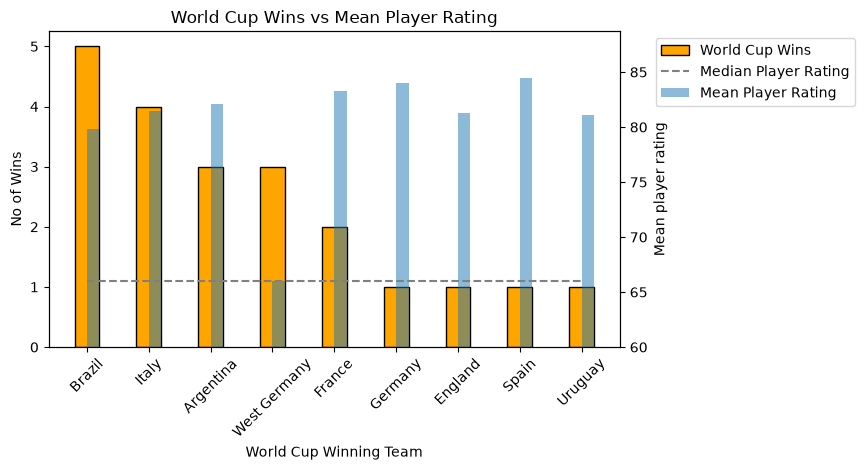

In [45]:
# correlate world_cup_winners vs mean player rating for that national team

fig, ax1 = plt.subplots()

# Bar plot - world cup wins
ax1.bar(world_cup_winners['match_winner'], world_cup_winners['count'], edgecolor='black', color='orange', width=0.4, align='center', label='World Cup Wins')
ax1.set_xlabel("World Cup Winning Team")
ax1.set_ylabel("No of Wins")
plt.xticks(rotation=45, fontsize=10)
plt.title("World Cup Wins vs Mean Player Rating")
plt.tight_layout()

# Bar plot - mean player rating (secondary axis)
x = winning_teams
y = winners_means
ax2 = ax1.twinx()
ax2.bar(winning_teams, winners_means, alpha=0.5, width=0.2, align='edge', label='Mean Player Rating')
ax2.set_ylabel('Mean player rating')
ax2.set_ylim(bottom=60)

# Line plot - median overall player rating (secondary axis)
med_ratings = np.repeat(med_rating, len(x))
ax2.plot(x, med_ratings, color='gray', linestyle='--', label='Median Player Rating')

handles, labels = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(handles + handles2, labels + labels2, bbox_to_anchor=(1.05, 1), loc='upper left')

## 8. Correlation Analysis

In [48]:
players_df_copy = players_df.copy()
players_df_copy = players_df_copy.select_dtypes(include=np.number)
players_df_copy.head()

,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,39,170.18,72.1,94,94,110500000.0,565000.0,5,4,4,...,94,48,22,94,94,75,96,33,28,26
1,34,154.94,76.2,88,89,69500000.0,205000.0,3,5,4,...,89,46,56,84,91,67,88,59,57,22
2,33,190.50,83.9,88,91,73000000.0,255000.0,4,4,5,...,82,78,64,82,88,82,87,63,67,67
3,35,162.56,59.0,88,88,62000000.0,165000.0,3,4,4,...,84,34,26,83,87,61,83,51,24,22
4,35,187.96,88.9,88,91,60000000.0,135000.0,3,3,2,...,15,87,88,24,49,33,80,91,88,87


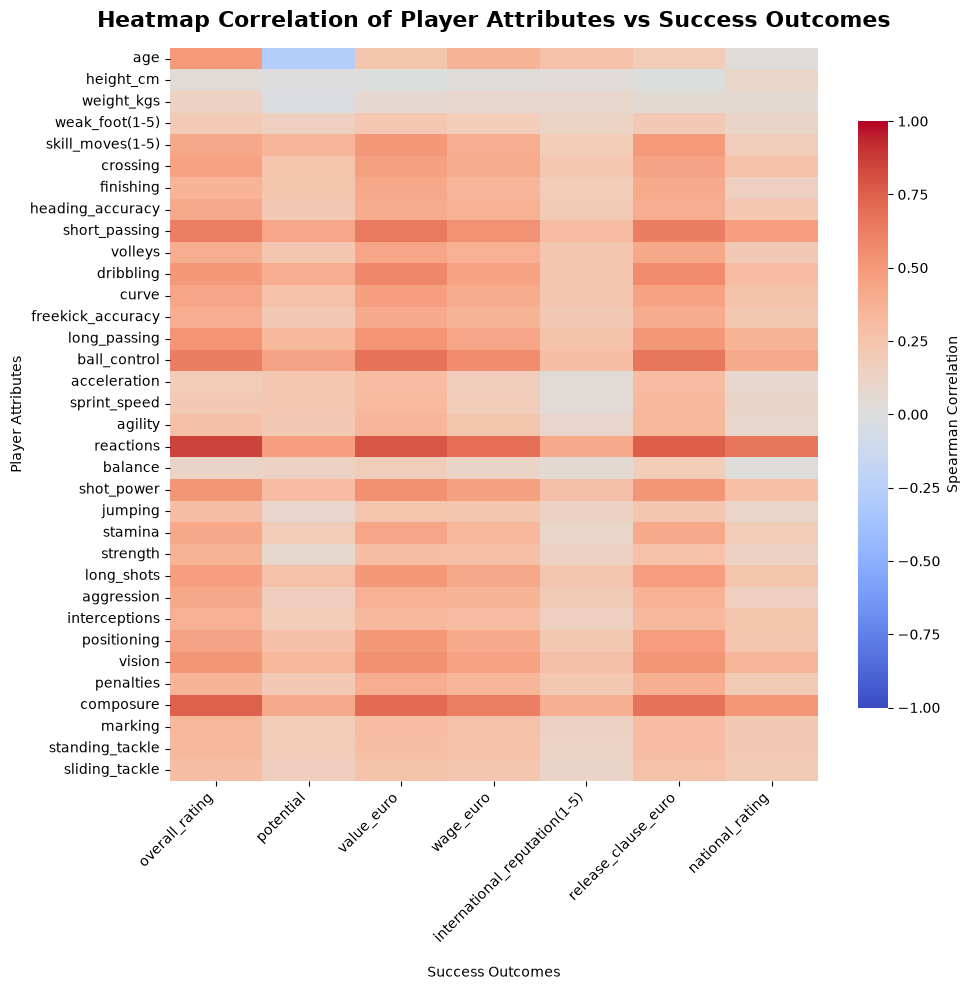

In [346]:
skills_attributes = players_df_copy.drop(columns=[ 'overall_rating', \
                                               'potential', 'value_euro', 'wage_euro', 'international_reputation(1-5)', \
                                                'release_clause_euro', 'national_rating', 'national_jersey_number'])

outcomes = players_df_copy[['overall_rating', 'potential', 'value_euro', 'wage_euro', 'international_reputation(1-5)', 'release_clause_euro', 'national_rating']]


label_data = []
spearman_data = []
temporary_list = []
spearman_scores = {}
empty_df = pd.DataFrame( index=skills_attributes.columns, columns = outcomes.columns)
previous_skill = None
for skill in skills_attributes.columns:
    for outcome in outcomes.columns:
        current_skill = skills_attributes[skill]
        current_outcome = outcomes[outcome]
        new_df = pd.DataFrame({str(skill): current_skill,
                               str(outcome): current_outcome})
        new_df.dropna(inplace=True)                
        current_score = (stats.spearmanr(new_df[skill], new_df[outcome]))
        #print(current_score.statistic)
        empty_df.at[skill, outcome] = current_score.statistic


spearmans_df = empty_df.astype(np.float64)
fig, ax = plt.subplots(figsize=(10,10))
plot = sns.heatmap(spearmans_df, cmap='coolwarm', cbar_kws={'shrink': 0.8, 'label': 'Spearman Correlation'}, center=0, vmin=-1,vmax=1)
ax.set_title("Heatmap Correlation of Player Attributes vs Success Outcomes", fontsize=16, pad=15, fontweight='bold')
ax.set_xlabel("Success Outcomes", labelpad=15)
ax.tick_params(axis='x', rotation=45)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
ax.set_ylabel("Player Attributes")
plt.tight_layout()


## 9. Additional Exploratory Analysis

In [305]:
'''most caps'''
most_caps = perform_df.groupby(['player_id']).count().sort_values(by='player_id', ascending=False)
most_caps.head(20)

,season_name,competition_id,competition_name,team_id,team_name,nb_in_group,nb_on_pitch,goals,assists,own_goals,subed_in,subed_out,yellow_cards,second_yellow_cards,direct_red_cards,penalty_goals,minutes_played,goals_conceded,clean_sheets
player_id,,,,,,,,,,,,,,,,,,,
1453181,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452964,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452836,2,2,2,2,2,2,2,1,2,2,2,2,2,2,2,2,1,2,2
1452157,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452156,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1452155,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1449325,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1449251,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2
1449249,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,0,2,2


In [53]:
# id's of most minutes played

most_mins_played = (perform_df.groupby(['player_id', 'team_name'])['minutes_played'].sum().sort_values(ascending=False).head(50).reset_index())
most_mins_played

,player_id,team_name,minutes_played
0,22415,Cruzeiro Esporte Clube,80748.0
1,15570,CSKA Moscow,72375.0
2,27796,Kashima Antlers,67196.0
3,3979,Real Madrid,64942.0
4,50144,Sport Club Corinthians Paulista,62143.0
5,5023,Juventus FC,61412.0
6,4582,Twente Enschede FC,60461.0
7,118487,Cerezo Osaka,57059.0
8,206,Bayern Munich,56617.0
9,23951,Olympique Marseille,55016.0


In [ ]:
# player_id's of most mins played:
most_mins_players = most_mins_played['player_id']

0      22415
1      15570
2      27796
3       3979
4      50144
5       5023
6       4582
7     118487
8        206
9      23951
10     55304
11     22229
12     39096
13     17259
14     58088
15     59377
16      7589
17      3692
18      7079
19     81787
20     87859
21     53786
22     29574
23    121483
24      9422
25     42631
26       891
27      5658
28     60561
29     39996
30     16911
31      9989
32     48064
33     45026
34    162695
35      3146
36      4860
37     35491
38     28021
39        26
40     17965
41      3357
42     69400
43     10242
44      3552
45     14043
46     29559
47      3575
48     74857
49     67867
Name: player_id, dtype: int64

In [315]:
# player names using player ids
matching_rows = pd.merge(most_mins_players, profiles_df, on='player_id', how='inner')
names = matching_rows[['player_name', 'citizenship']]
names

# split citizenship if 2 spaces between country names, and keep the first one (birth citizenship)

def remove_last_country(lst):
    '''Removes last country name in list if there is more than 1'''
    if len(lst) > 1:
        lst.pop()
    return lst

names['citizenship'] = names['citizenship'].str.split('  ').apply(remove_last_country)
names['citizenship'] = (names['citizenship']).str[0]
names.head()


,player_name,citizenship
0,Fábio (22415),Brazil
1,Igor Akinfeev (15570),Russia
2,Hitoshi Sogahata (27796),Japan
3,Iker Casillas (3979),Spain
4,Cássio (50144),Brazil


In [316]:
'''most common citizenship of players with most play-time'''

mode_citizenship_play = names.groupby('citizenship').agg(player_names=('player_name', list), count=('player_name', 'count')).sort_values(by='count', ascending=False)
mode_citizenship_play.head()

,player_names,count
citizenship,,
Germany,"[Oliver Kahn (206), Martin Männel (39096), Man...",6
Brazil,"[Fábio (22415), Cássio (50144), Magrão (55304)...",6
France,"[Steve Mandanda (23951), Hugo Lloris (17965), ...",4
England,"[Paul Harrison (22229), Kevin Pressman (10242)...",3
Spain,"[Iker Casillas (3979), David de Gea (59377), V...",3


In [311]:
most_caps_players = pd.merge(most_caps, profiles_df, on='player_id', how='inner')
names_most_caps = most_caps_players[['player_name', 'citizenship']]
names_most_caps

,player_name,citizenship
0,Modou Jassey (1453181),Italy
1,Simone Meriggi (1452964),Italy
2,Santino Perrone (1452836),Italy
3,Bünyamin Oklu (1452157),Türkiye
4,Hasan Dağlı (1452156),Türkiye
...,...,...
88370,Petr Gabriel (5),Czech Republic
88371,Youri Djorkaeff (4),France Armenia
88372,Andreas Buck (3),Germany
88373,Mario Basler (2),Germany


In [320]:
'''most common citizenship of players with most caps'''
mode_citizenship_caps = names_most_caps.groupby('citizenship').agg(player_names=('player_name', list), count=('player_name', 'count')).sort_values(by='count', ascending=False)
mode_citizenship_caps.head(10)

,player_names,count
citizenship,,
Italy,"[Modou Jassey (1453181), Simone Meriggi (14529...",11146
Spain,"[Lamine Gueye (1434744), Haitz Huete Gómez (14...",5672
Brazil,"[Neto (1422478), Willian Silva (1390655), Davi...",5368
England,"[Charlie Warren (1416999), Caleb Sanders (1407...",3987
France,"[Maxime Murer (1416886), Paul Bougrat (1412163...",3496
Germany,"[Caner Ari (1434540), Fabio Lettieri (1399703)...",3130
Türkiye,"[Bünyamin Oklu (1452157), Hasan Dağlı (1452156...",2938
Portugal,"[Henrique Lopes (1431410), Carlos Daniel (1426...",2034
Argentina,"[Lucas Medina (1408539), Isaias Penida (138645...",1829


## 9. Machine Learning Analysis

## 10. Conclusions